# Car Plates Number Detection

In [ ]:
import pandas as pd
import numpy as np

## Dataset: Indian Vehicle license plate datset

[Kaggle Indian Vehicle license plate datset](https://www.kaggle.com/datasets/saisirishan/indian-vehicle-dataset?)

In [ ]:
!pip install kagglehub
import kagglehub
import os
dataset_path = kagglehub.dataset_download(
    "saisirishan/indian-vehicle-dataset"
)

print("Dataset downloaded to:")
print(dataset_path)

Using Colab cache for faster access to the 'indian-vehicle-dataset' dataset.
Dataset downloaded to:
/kaggle/input/indian-vehicle-dataset


## Convert to Gray Scale

In [ ]:
def convertRGBToGrayscale(img):
    gray_img = np.zeros((img.shape[0], img.shape[1]))

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            R = img[i][j][0]
            G = img[i][j][1]
            B = img[i][j][2]

            gray = 0.299 * R + 0.587 * G + 0.114 * B
            gray_img[i][j] = gray

    return gray_img

## Remove Noise

In [ ]:
def gaussian(img, kernel=3):
    kernel_matrix = np.array([
        [1, 2, 1],
        [2, 4, 2],
        [1, 2, 1]
    ]) / 16

    pad = kernel // 2
    padded_img = np.pad(img, pad, mode='constant')

    nonNoisyImg = np.zeros_like(img)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):

            region = padded_img[i:i+kernel, j:j+kernel]

            nonNoisyImg[i, j] = np.sum(region * kernel_matrix)

    return nonNoisyImg


# Median
def median(img, kernel=3):
    pad = kernel // 2
    padded_img = np.pad(img, pad, mode='constant')

    nonNoisyImg = np.zeros_like(img)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):

            region = padded_img[i:i+kernel, j:j+kernel]

            nonNoisyImg[i, j] = np.median(region)

    return nonNoisyImg


## Histogram From Scratch

In [ ]:
def histogram(img):

    if len(img.shape) == 3:
        img = convertRGBToGrayscale(img)

    hist = np.zeros(256)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            pixel = int(img[i, j])
            hist[pixel] += 1

    return hist

## Sobel

In [ ]:
def sobel(img):

    if len(img.shape) == 3:
        img  = convertRGBToGrayscale(img)

    # Sobel kernels
    Gx_kernel = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ])

    Gy_kernel = np.array([
        [ 1,  2,  1],
        [ 0,  0,  0],
        [-1, -2, -1]
    ])

    h, w = img.shape
    padded = np.pad(img, 1, mode='constant')

    result = np.zeros((h, w))

    for i in range(h):
        for j in range(w):

            region = padded[i:i+3, j:j+3]

            gx = np.sum(region * Gx_kernel)
            gy = np.sum(region * Gy_kernel)

            result[i, j] = np.sqrt(gx**2 + gy**2)

    return result

## Read Data

In [ ]:
import cv2
import matplotlib.pyplot as plt

image_paths = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(('.jpg', '.png', '.jpeg')):
            image_paths.append(os.path.join(root, file))

print("Total images:", len(image_paths))

Total images: 1698


## Image Filtering Visualization

### Apply GreyScale, Gaussian, Median Filters

==== Image 1 ====


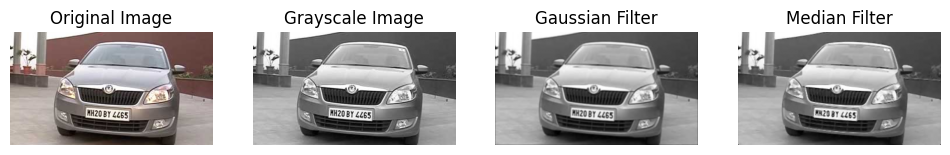

==== Image 2 ====


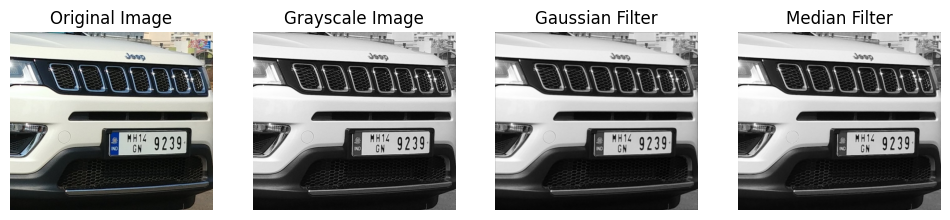

==== Image 3 ====


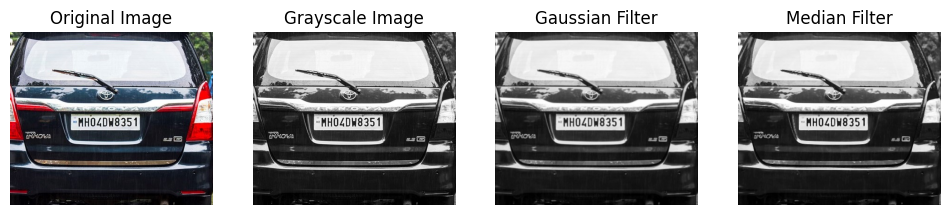

==== Image 4 ====


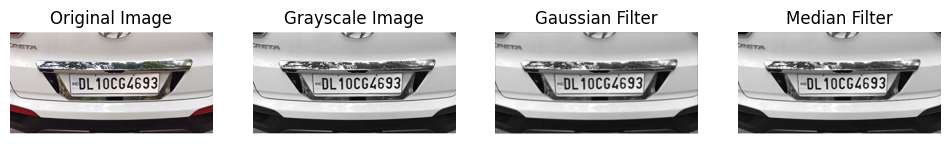

==== Image 5 ====


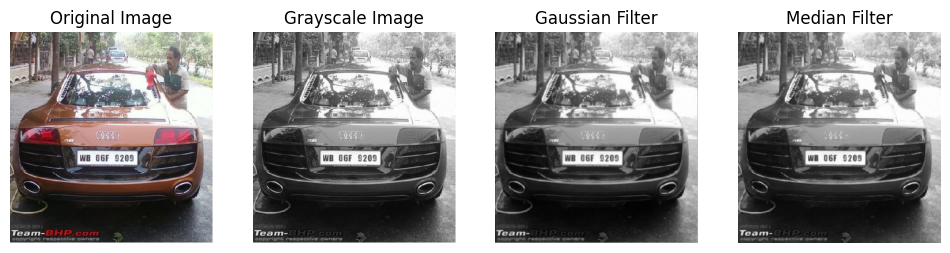

In [ ]:
for count, path in enumerate(image_paths[:5], start=1):

    img = cv2.imread(path)

    print(f"==== Image {count} ====")

    h, w, _ = img.shape

    plt.figure(figsize=(12, 4))

    # Original
    plt.subplot(1, 4, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis('off')

    # Grayscale
    img_gray = convertRGBToGrayscale(img)

    plt.subplot(1, 4, 2)
    plt.imshow(img_gray, cmap='gray')
    plt.title("Grayscale Image")
    plt.axis('off')

    # Gaussian
    apply_gaussian = gaussian(img_gray)

    plt.subplot(1, 4, 3)
    plt.imshow(apply_gaussian, cmap='gray')
    plt.title("Gaussian Filter")
    plt.axis('off')

    # Median
    apply_median = median(img_gray)

    plt.subplot(1, 4, 4)
    plt.title("Median Filter")
    plt.imshow(apply_median, cmap='gray')
    plt.axis('off')

    plt.show()

### Apply Histogaram

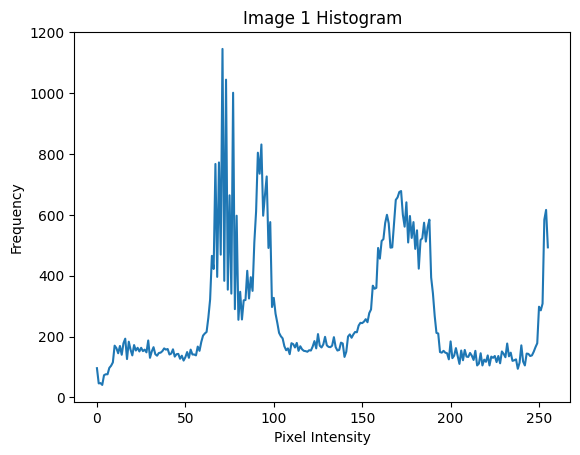

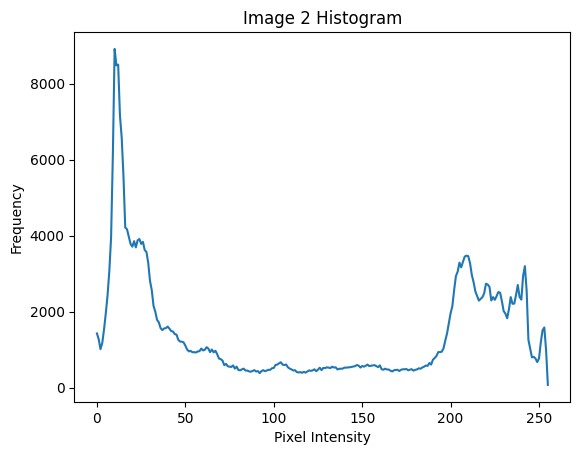

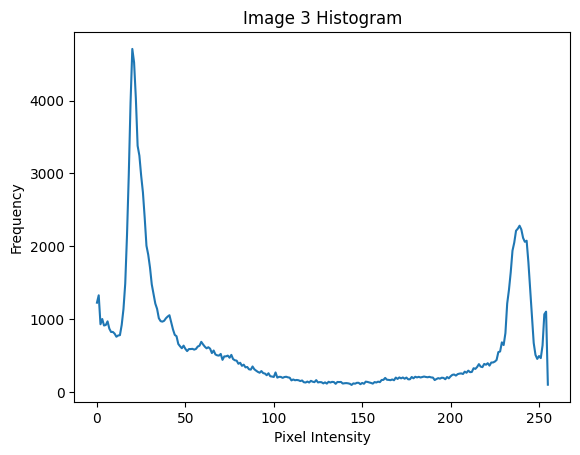

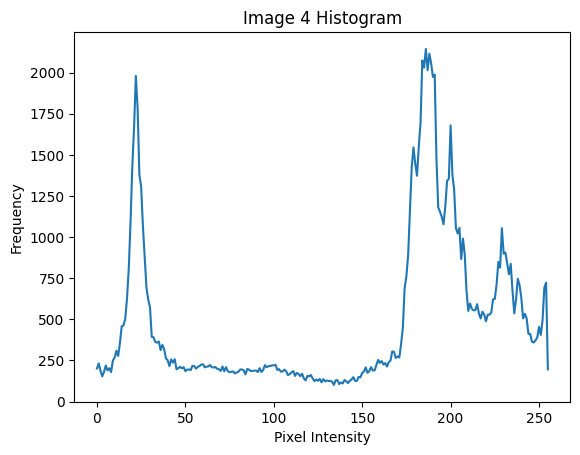

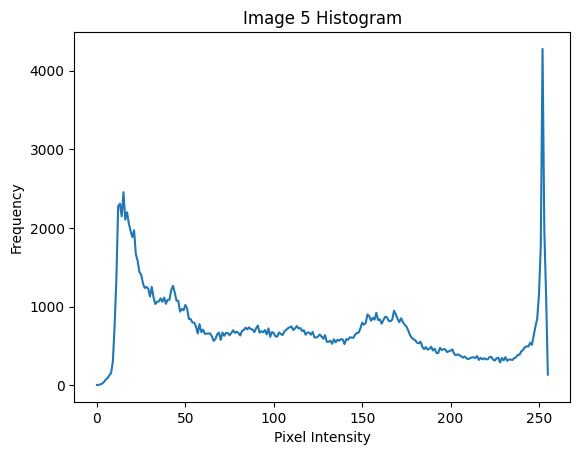

In [ ]:
import matplotlib.pyplot as plt
for count, path in enumerate(image_paths[:5], start=1):
    img = cv2.imread(path)

    hist = histogram(img)

    plt.figure()

    plt.plot(hist)
    plt.title(f"Image {count} Histogram")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")

    plt.show()

### Apply Sobel

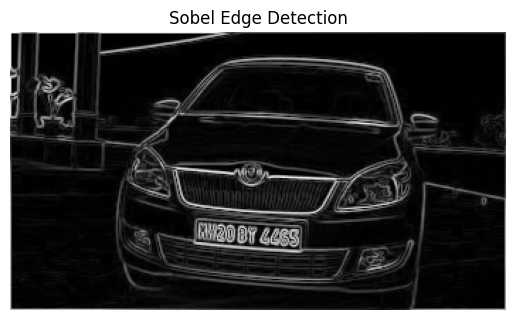

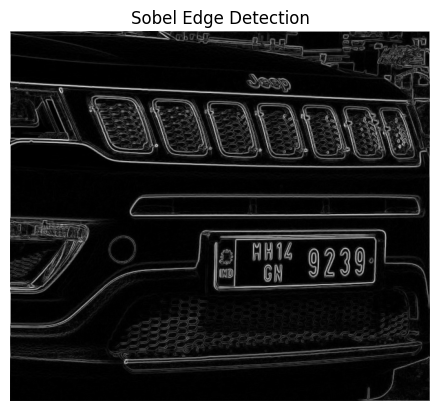

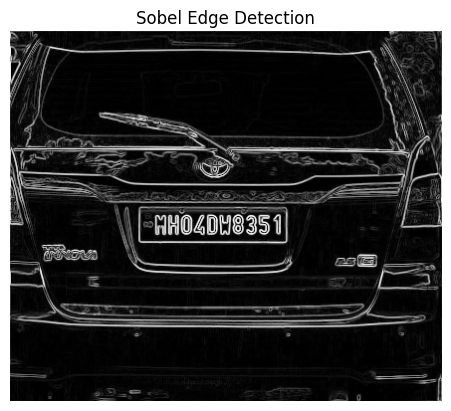

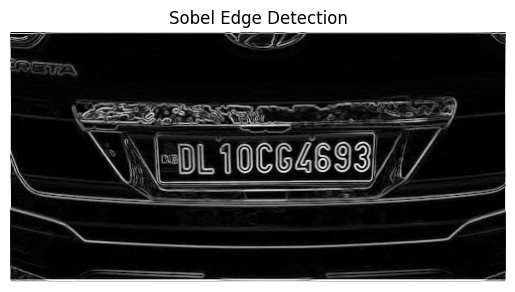

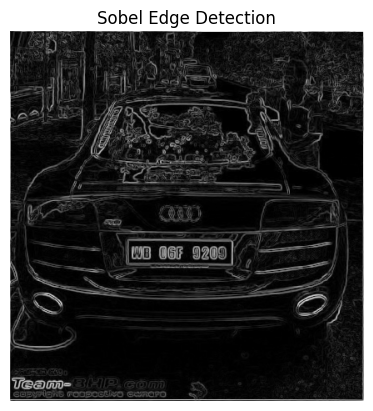

In [ ]:
for count, path in enumerate(image_paths[:5], start=1):
    img = cv2.imread(path)
    edge_img = sobel(img)
    plt.imshow(edge_img, cmap='gray')
    plt.title("Sobel Edge Detection")
    plt.axis('off')
    plt.show()

## Image Segmentation

### Thresholding
Convert the grayscale image into a black and white image.

To help separate the plate from the car.

In [ ]:
def binaryThreshold(gray_image, threshold_value=120):

    binary_image = np.zeros_like(gray_image)

    for row in range(gray_image.shape[0]):
        for col in range(gray_image.shape[1]):

            pixel_value = gray_image[row, col]

            if pixel_value > threshold_value:
                binary_image[row, col] = 255
            else:
                binary_image[row, col] = 0

    return binary_image

### Dilation
Expand white / black regions.

To help:Connect broken edges -
Make plate borders stronger

In [ ]:
def dilation(binary_image):

    kernel = np.ones((3,3))

    padded_image = np.pad(binary_image, 1)

    dilated_image = np.zeros_like(binary_image)

    for row in range(binary_image.shape[0]):
        for col in range(binary_image.shape[1]):

            region = padded_image[row:row+3, col:col+3]

            if np.max(region * kernel) > 0:
                dilated_image[row, col] = 255

    return dilated_image

In [ ]:
def dilationBlack(binary_image):

    kernel = np.ones((3,3))

    padded_image = np.pad(binary_image, 1, constant_values=255)

    dilated_image = np.full_like(binary_image, 255)

    for row in range(binary_image.shape[0]):
        for col in range(binary_image.shape[1]):

            region = padded_image[row:row+3, col:col+3]

            if np.min(region) == 0:
                dilated_image[row, col] = 0

    return dilated_image

### Erosion
Removes small white/ black noise.

This helps: Clean the image -
Keep only strong regions

In [ ]:
def erosion(binary_image):

    kernel = np.ones((3,3))

    padded_image = np.pad(binary_image, 1)

    eroded_image = np.zeros_like(binary_image)

    for row in range(binary_image.shape[0]):
        for col in range(binary_image.shape[1]):

            region = padded_image[row:row+3, col:col+3]

            if np.min(region * kernel) == 255:
                eroded_image[row, col] = 255

    return eroded_image

In [ ]:
def erosionBlack(binary_image):

    kernel = np.ones((3,3))

    padded_image = np.pad(binary_image, 1, constant_values=255)

    eroded_image = np.full_like(binary_image, 255)

    for row in range(binary_image.shape[0]):
        for col in range(binary_image.shape[1]):

            region = padded_image[row:row+3, col:col+3]

            if np.max(region) == 0:
                eroded_image[row, col] = 0

    return eroded_image


### Connected Componenets Detection
Find all connected white regions in the image.

Later we filter them.

In [ ]:
def connectedComponents(binary_image):

    visited = np.zeros_like(binary_image)

    components = []

    rows = binary_image.shape[0]
    cols = binary_image.shape[1]

    directions = [
        (-1,0), (1,0),
        (0,-1), (0,1)
    ]

    for row in range(rows):
        for col in range(cols):

            if binary_image[row, col] == 255 and visited[row, col] == 0:

                stack = [(row, col)]

                visited[row, col] = 1

                current_component = []

                while stack:

                    current_row, current_col = stack.pop()

                    current_component.append((current_row, current_col))

                    for dx, dy in directions:

                        new_row = current_row + dx
                        new_col = current_col + dy

                        if (
                            0 <= new_row < rows and
                            0 <= new_col < cols and
                            binary_image[new_row, new_col] == 255 and
                            visited[new_row, new_col] == 0
                        ):

                            visited[new_row, new_col] = 1
                            stack.append((new_row, new_col))

                components.append(current_component)

    return components

In [ ]:
def connectedComponentsBlack(binary_image):

    visited = np.zeros_like(binary_image)

    components = []

    rows = binary_image.shape[0]
    cols = binary_image.shape[1]

    directions = [
        (-1,0), (1,0),
        (0,-1), (0,1)
    ]

    for row in range(rows):
        for col in range(cols):

            if binary_image[row, col] == 0 and visited[row, col] == 0:

                stack = [(row, col)]

                visited[row, col] = 1

                current_component = []

                while stack:

                    current_row, current_col = stack.pop()

                    current_component.append((current_row, current_col))

                    for dx, dy in directions:

                        new_row = current_row + dx
                        new_col = current_col + dy

                        if (
                            0 <= new_row < rows and
                            0 <= new_col < cols and
                            binary_image[new_row, new_col] == 0 and
                            visited[new_row, new_col] == 0
                        ):

                            visited[new_row, new_col] = 1
                            stack.append((new_row, new_col))

                components.append(current_component)

    return components

### Plate Candidate Detection
Filters regions based on:

Width /
Height /
Aspect ratio

In [ ]:
def detectPlateRegions(original_image, connected_regions):

    image_copy = original_image.copy()

    possible_plates = []

    for region in connected_regions:

        rows = [pixel[0] for pixel in region]
        cols = [pixel[1] for pixel in region]

        min_row = min(rows)
        max_row = max(rows)

        min_col = min(cols)
        max_col = max(cols)

        width = max_col - min_col
        height = max_row - min_row

        if height == 0:
            continue

        aspect_ratio = width / height

        # Plate filtering conditions
        if (
            width > 60 and
            height > 20 and
            2 < aspect_ratio < 6
        ):

            possible_plates.append((min_row, max_row, min_col, max_col))

            cv2.rectangle(
                image_copy,
                (min_col, min_row),
                (max_col, max_row),
                (0,255,0),
                2
            )

    return image_copy, possible_plates

In [ ]:
def segmentCharacters(binary_plate):
    plate_h, plate_w = binary_plate.shape

    white_pixels = np.sum(binary_plate == 255)
    black_pixels = np.sum(binary_plate == 0)

    if black_pixels < white_pixels:
        components = connectedComponentsBlack(binary_plate)
    else:
        components = connectedComponents(binary_plate)

    char_regions = []

    for component in components:
        rows = [p[0] for p in component]
        cols = [p[1] for p in component]

        min_row, max_row = min(rows), max(rows)
        min_col, max_col = min(cols), max(cols)

        char_h = max_row - min_row
        char_w = max_col - min_col

        if char_h == 0 or char_w == 0:
            continue

        aspect_ratio = char_w / char_h

        passed = (
            plate_h * 0.2 < char_h < plate_h * 2 and
            2 < char_w < plate_w * 0.5 and
            0.1 < aspect_ratio < 2.0
        )


        if passed:
            char_regions.append((min_row, max_row, min_col, max_col))

    char_regions.sort(key=lambda r: r[2])
    return char_regions

In [ ]:
def normalizeCharacter(char_img, size=(50, 50)):
    target_h, target_w = size

    src_h, src_w = char_img.shape
    if src_h == 0 or src_w == 0:
        return np.zeros(size, dtype=np.uint8)

    resized = np.zeros(size, dtype=np.uint8)

    for i in range(target_h):
        for j in range(target_w):
            src_i = int(i * src_h / target_h)
            src_j = int(j * src_w / target_w)
            resized[i, j] = char_img[src_i, src_j]

    return resized

In [ ]:
def selectBestPlate(plate_regions, edge_image):

    best_region = None
    best_score = -1

    for region in plate_regions:

        min_row, max_row, min_col, max_col = region

        h = max_row - min_row
        w = max_col - min_col

        if h == 0 or w == 0:
            continue

        area = h * w
        aspect_ratio = w / h

        roi = edge_image[min_row:max_row, min_col:max_col]

        if roi.size == 0:
            continue

        roi = (roi > 0).astype(np.uint8)

        # 1. Edge density
        edge_density = np.sum(roi) / roi.size

        # 2. Edge variance (important for structure)
        edge_variance = np.var(roi)

        # 3. Horizontal projection (plates have aligned digits)
        horizontal_sum = np.sum(roi, axis=1)
        horizontal_score = np.std(horizontal_sum)

        # ===== scoring =====
        score = 0

        # aspect ratio of plates
        if 2.5 < aspect_ratio < 6.5:
            score += 3

        # reasonable size
        if area > 2000:
            score += 2

        # edge density sweet spot (not too low, not too high)
        if 0.05 < edge_density < 0.25:
            score += 4
        else:
            score -= 2

        # structure (important upgrade)
        score += edge_variance * 3

        # horizontal alignment (very important for numbers)
        score += horizontal_score * 0.01

        # penalty for noisy regions
        if edge_density > 0.4:
            score -= 3


        score += np.log(area + 1) * 0.3

        if score > best_score:
            best_score = score
            best_region = region

    return best_region

In [ ]:
def extractCharacters(rgb_image, plate_regions, edge_image, char_size=(40, 40)):

    all_plates_chars = []

    best_region = selectBestPlate(plate_regions, edge_image)

    if best_region is None:
        return all_plates_chars

    plate_crop = cropPlate(rgb_image, best_region)

    if plate_crop.size == 0:
        return all_plates_chars

    binary_plate, gray_plate = thresholdPlate(plate_crop)

    char_regions = segmentCharacters(binary_plate)

    normalized_chars = []

    for (r1, r2, c1, c2) in char_regions:

        char_img = binary_plate[r1:r2, c1:c2]

        if char_img.size == 0:
            continue

        normalized = normalizeCharacter(char_img, size=char_size)

        normalized_chars.append({
            "image": normalized,
            "bbox": (r1, r2, c1, c2)
        })

    all_plates_chars.append({
        "plate_crop": plate_crop,
        "gray_plate": gray_plate,
        "binary_plate": binary_plate,
        "characters": normalized_chars
    })

    return all_plates_chars

### Segmentation Full Pipeline
Runs the complete segmentation pipeline:

Grayscale,
Gaussian,
Sobel,
Threshold,
Morphology,
Connected components,
Plate detection

In [ ]:
def cropPlate(image, plate_region):
    min_row, max_row, min_col, max_col = plate_region
    return image[min_row:max_row, min_col:max_col]


In [ ]:
def thresholdPlate(plate_crop):
    gray = convertRGBToGrayscale(plate_crop) if len(plate_crop.shape) == 3 else plate_crop
    return binaryThreshold(gray, threshold_value=128), gray


========== IMAGE 1 ==========


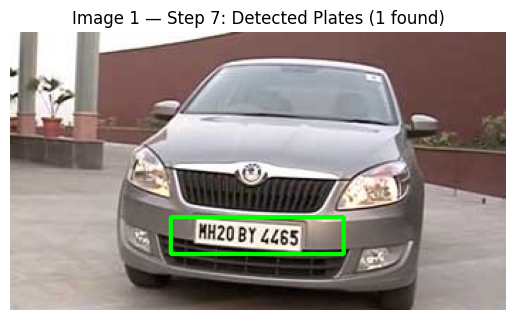

  Plate 1: 10 character(s) found


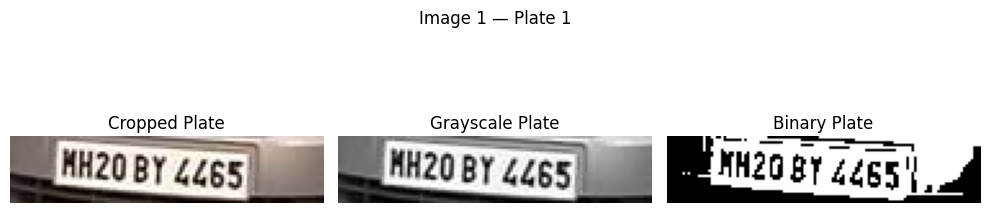

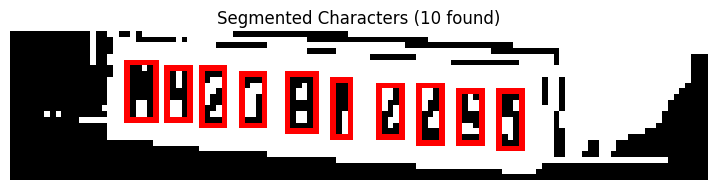

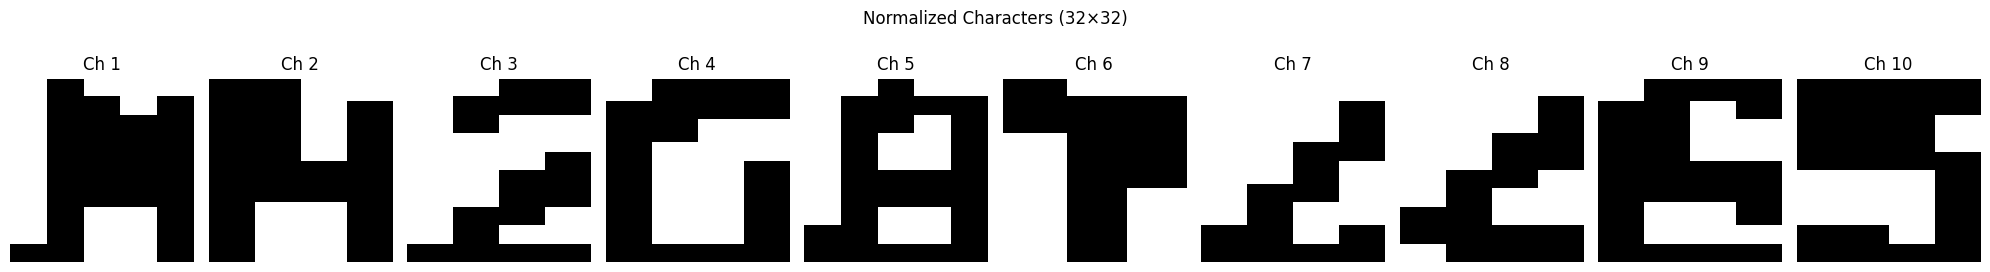

========== IMAGE 2 ==========


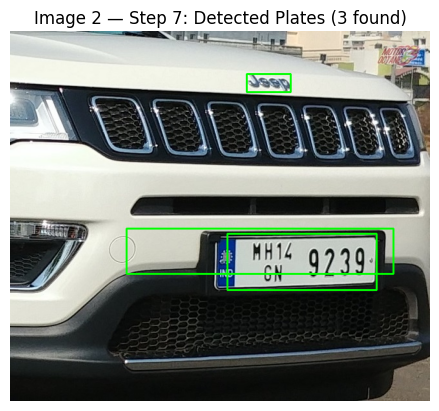

  Plate 1: 8 character(s) found


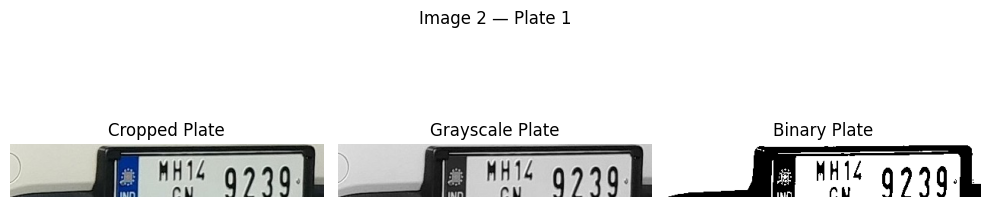

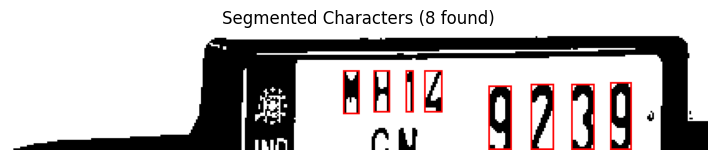

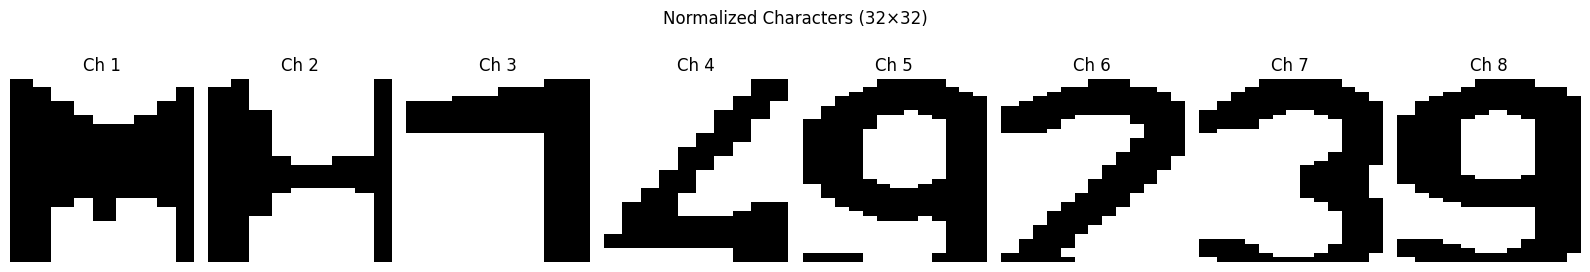

========== IMAGE 3 ==========


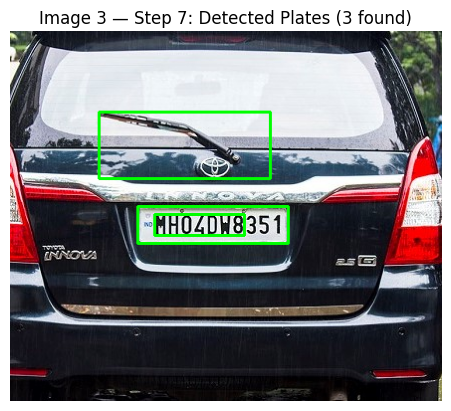

  Plate 1: 0 character(s) found


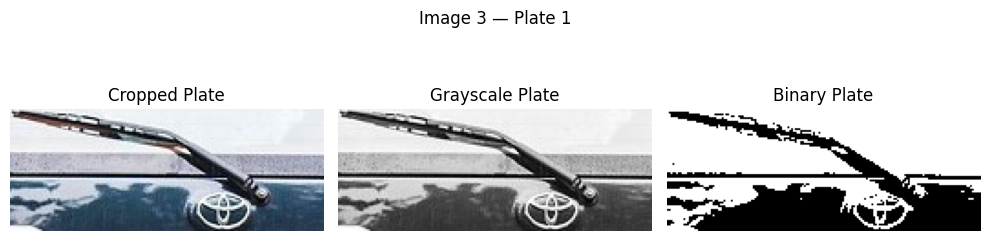

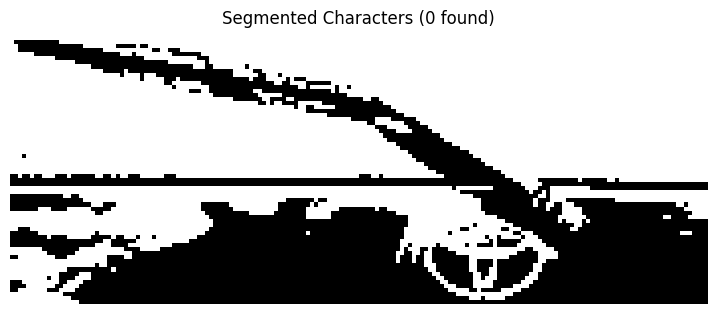

========== IMAGE 4 ==========


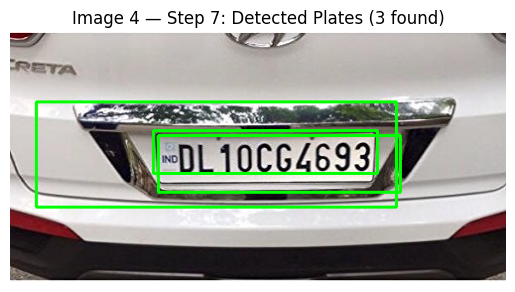

  Plate 1: 10 character(s) found


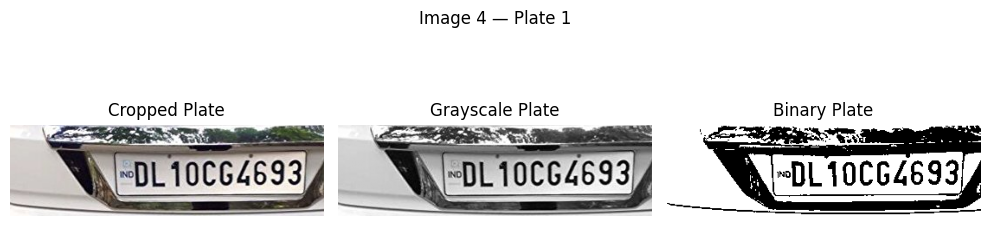

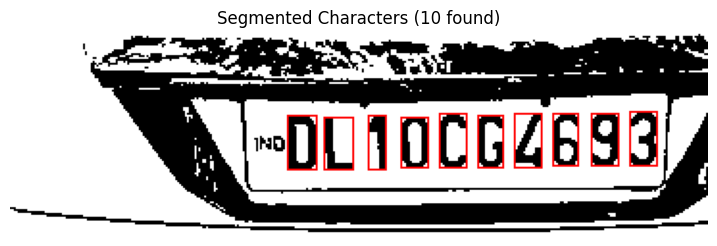

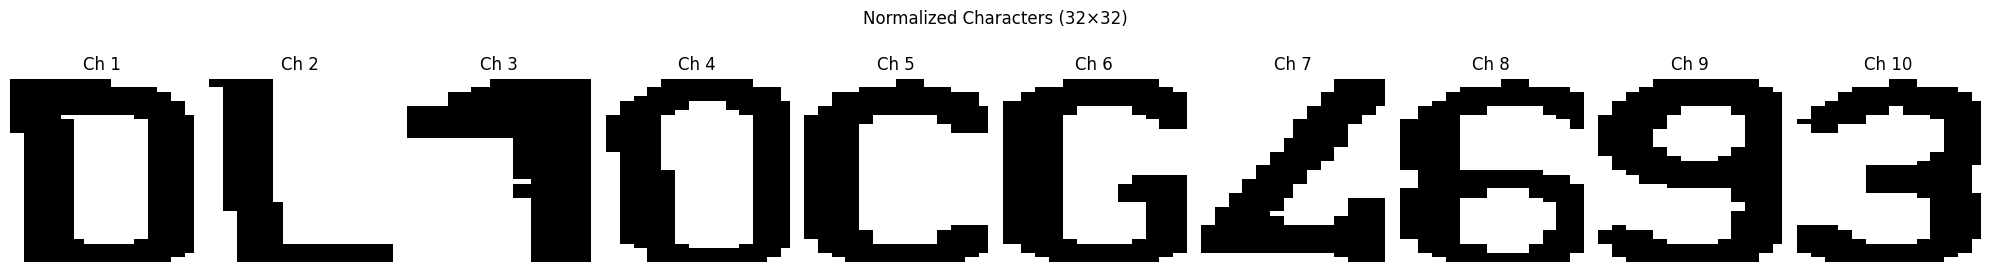

========== IMAGE 5 ==========


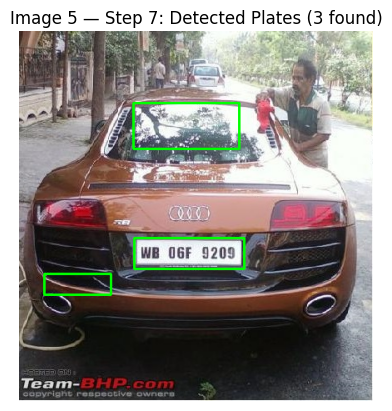

  Plate 1: 9 character(s) found


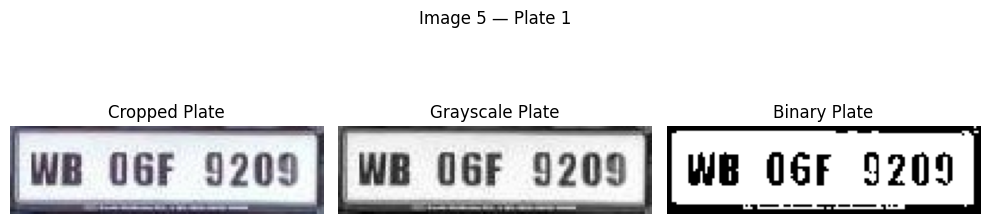

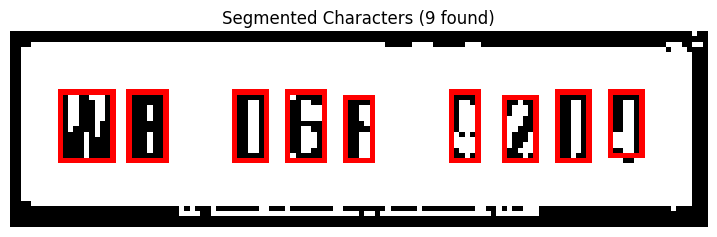

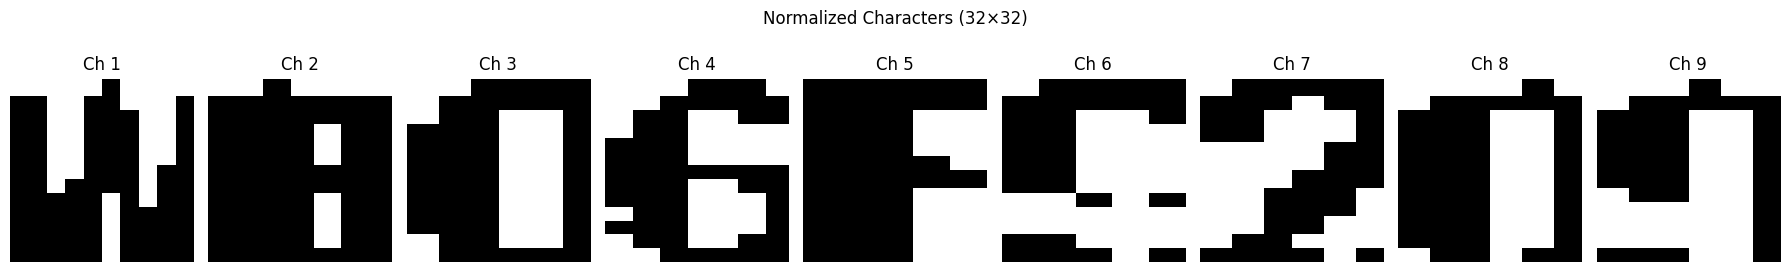

In [ ]:
for image_number, image_path in enumerate(image_paths[:5], start=1):

    print(f"========== IMAGE {image_number} ==========")

    car_image = cv2.imread(image_path)
    rgb_image = cv2.cvtColor(car_image, cv2.COLOR_BGR2RGB)

    # Step 1: Convert to grayscale
    gray_image = convertRGBToGrayscale(rgb_image)

    # plt.imshow(gray_image, cmap='gray')
    # plt.title(f"Image {image_number} — Step 1: Grayscale")
    # plt.axis('off')
    # plt.show()

    # Step 2: Remove noise
    smooth_image = gaussian(gray_image)

    # plt.imshow(smooth_image, cmap='gray')
    # plt.title(f"Image {image_number} — Step 2: Gaussian Smoothing")
    # plt.axis('off')
    # plt.show()

    # Step 3: Detect edges
    edge_image = sobel(smooth_image)

    # plt.imshow(edge_image, cmap='gray')
    # plt.title(f"Image {image_number} — Step 3: Sobel Edge Detection")
    # plt.axis('off')
    # plt.show()

    # Step 4: Convert to binary image
    binary_image = binaryThreshold(edge_image, 100)

    # plt.imshow(binary_image, cmap='gray')
    # plt.title(f"Image {image_number} — Step 4: Binary Threshold")
    # plt.axis('off')
    # plt.show()

    # Step 5: Morphological operations
    dilated_image = dilationBlack(binary_image)

    # plt.imshow(dilated_image, cmap='gray')
    # plt.title(f"Image {image_number} — Step 5a: Dilation")
    # plt.axis('off')
    # plt.show()

    cleaned_image = erosionBlack(dilated_image)

    # plt.imshow(cleaned_image, cmap='gray')
    # plt.title(f"Image {image_number} — Step 5b: Erosion (Cleaned)")
    # plt.axis('off')
    # plt.show()

    # Step 6: Connected components
    detected_regions = connectedComponents(cleaned_image)

    # label_image = np.zeros_like(cleaned_image)
    # for i, region in enumerate(detected_regions):
    #     intensity = (i * 37 % 255) + 1
    #     for (r, c) in region:
    #         label_image[r, c] = intensity

    # plt.imshow(label_image, cmap='nipy_spectral')
    # plt.title(f"Image {image_number} — Step 6: Connected Components ({len(detected_regions)} regions)")
    # plt.axis('off')
    # plt.show()

    # Step 7: Detect possible plates
    result_image, plate_regions = detectPlateRegions(rgb_image, detected_regions)

    plt.imshow(result_image)
    plt.title(f"Image {image_number} — Step 7: Detected Plates ({len(plate_regions)} found)")
    plt.axis('off')
    plt.show()

    results = extractCharacters(rgb_image, plate_regions, edge_image)

    # for idx, region in enumerate(plate_regions):
    #     best_region = selectBestPlate(plate_regions)
    #     best_crop = cropPlate(rgb_image, best_region)
    #     binary_plate, gray_plate = thresholdPlate(best_crop)

    #     plt.imshow(binary_plate, cmap='gray')
    #     plt.title(f"Image {image_number} — Best Plate")
    #     plt.axis('off')
    #     plt.show()

    for plate_idx, plate_data in enumerate(results):
        chars = plate_data["characters"]
        print(f"  Plate {plate_idx + 1}: {len(chars)} character(s) found")

        # Row 1: plate crop → gray → binary
        fig, axes = plt.subplots(1, 3, figsize=(10, 3))
        axes[0].imshow(plate_data["plate_crop"])
        axes[0].set_title("Cropped Plate")
        axes[0].axis("off")

        axes[1].imshow(plate_data["gray_plate"], cmap="gray")
        axes[1].set_title("Grayscale Plate")
        axes[1].axis("off")

        axes[2].imshow(plate_data["binary_plate"], cmap="gray")
        axes[2].set_title("Binary Plate")
        axes[2].axis("off")

        plt.suptitle(f"Image {image_number} — Plate {plate_idx + 1}")
        plt.tight_layout()
        plt.show()

        # Row 2: annotated binary plate showing bounding boxes
        annotated = cv2.cvtColor(
            plate_data["binary_plate"].astype(np.uint8), cv2.COLOR_GRAY2RGB
        )
        for ch in chars:
            r1, r2, c1, c2 = ch["bbox"]
            cv2.rectangle(annotated, (c1, r1), (c2, r2), (255, 0, 0), 1)

        plt.figure(figsize=(9, 5))
        plt.imshow(annotated)
        plt.title(f"Segmented Characters ({len(chars)} found)")
        plt.axis("off")
        plt.show()

        # Row 3: each normalized character
        if chars:
            n = len(chars)
            fig, axes = plt.subplots(1, n, figsize=(n * 2, 3))
            if n == 1:
                axes = [axes]
            for idx, ch in enumerate(chars):
                axes[idx].imshow(ch["image"], cmap="gray")
                axes[idx].set_title(f"Ch {idx + 1}")
                axes[idx].axis("off")
            plt.suptitle("Normalized Characters (32×32)")
            plt.tight_layout()
            plt.show()


## Character Recognition



### Feature Extraction

In [ ]:
def extractFeatures(char_img):

    features = []

    for row in range(char_img.shape[0]):
        for col in range(char_img.shape[1]):
            features.append(char_img[row, col] / 255.0)

    return np.array(features)

In [ ]:
import os
import cv2
import numpy as np
import kagglehub
import tarfile

# Download dataset
path = kagglehub.dataset_download("supreethrao/chars74kdigitalenglishfont")

print("Dataset path:", path)

# Extract .tgz file
tgz_path = os.path.join(path, "EnglishFnt.tgz")
extract_path = "/content/chars74k"

with tarfile.open(tgz_path, "r:gz") as tar:
    tar.extractall(path=extract_path)

print("Extracted to:", extract_path)


train_features = []
train_labels = []

for root, dirs, files in os.walk(extract_path):

    for file in files:

        if file.lower().endswith((".png", ".jpg", ".jpeg")):

            img_path = os.path.join(root, file)

            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

            if img is None:
                continue

            img = cv2.resize(img, (40, 40))
            feature_vector = img.flatten() / 255.0

            folder_name = os.path.basename(root)

            if folder_name.startswith("Sample"):

                sample_number = int(
                    folder_name.replace("Sample", "")
                )

                character_map = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"

                label = character_map[sample_number - 1]

                train_features.append(feature_vector)
                train_labels.append(label)

train_features = np.array(train_features)
train_labels = np.array(train_labels)

print("Training samples:", len(train_features))

Using Colab cache for faster access to the 'chars74kdigitalenglishfont' dataset.
Dataset path: /kaggle/input/chars74kdigitalenglishfont


/tmp/ipykernel_3831/3855962530.py:17: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Extracted to: /content/chars74k
Training samples: 62992


### KNN Classification From Scratch

In [ ]:
def euclideanDistance(vec1, vec2):
    return np.sqrt(np.sum((vec1 - vec2) ** 2))

def knnPredict(test_feature, train_features, train_labels, k=3):

    distances = []

    for i in range(len(train_features)):
        dist = euclideanDistance(test_feature, train_features[i])
        distances.append((dist, train_labels[i]))

    distances.sort(key=lambda x: x[0])
    nearest = distances[:k]

    votes = {}

    for _, label in nearest:
        votes[label] = votes.get(label, 0) + 1

    return max(votes, key=votes.get)


### Recognize Characters From Plate

In [ ]:
def recognizePlate(characters, train_features, train_labels):

    plate_text = ""

    for char_data in characters:

        char_img = char_data["image"]
        char_img = cv2.resize(char_img, (40, 40))
        feature_vector = char_img.flatten() / 255.0

        predicted_char = knnPredict(
            feature_vector,
            train_features,
            train_labels,
            k=3
        )

        plate_text += str(predicted_char)

    return plate_text

### Chars74K Pipeline

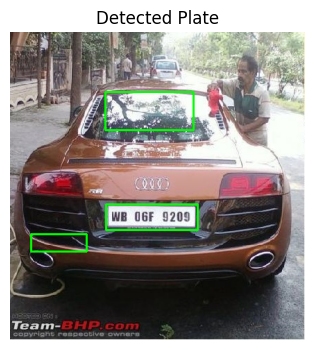

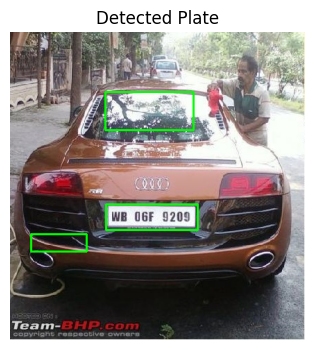

Detected Plate Text: MKKNnzM2AM


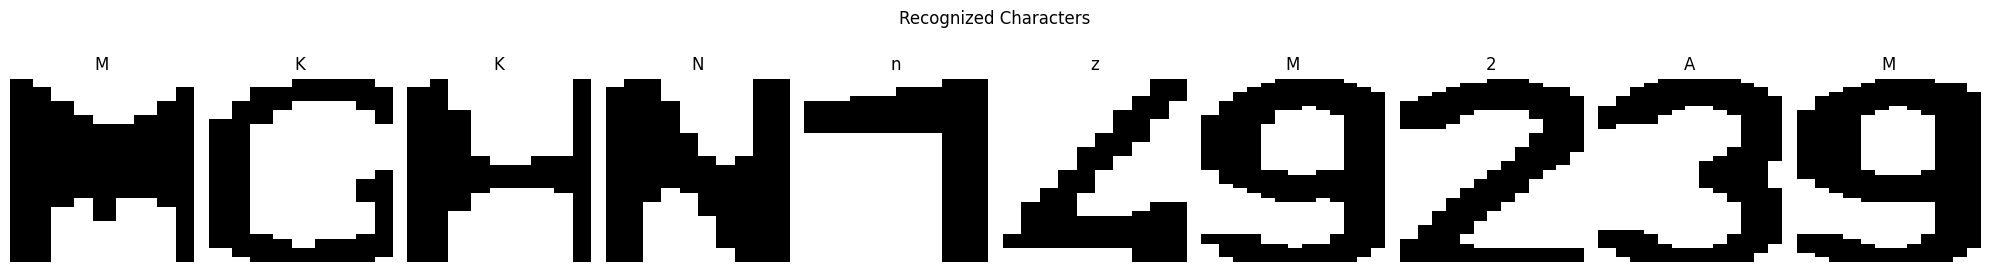

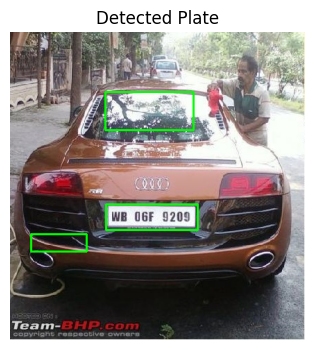

Detected Plate Text: MKKzKhHAKq


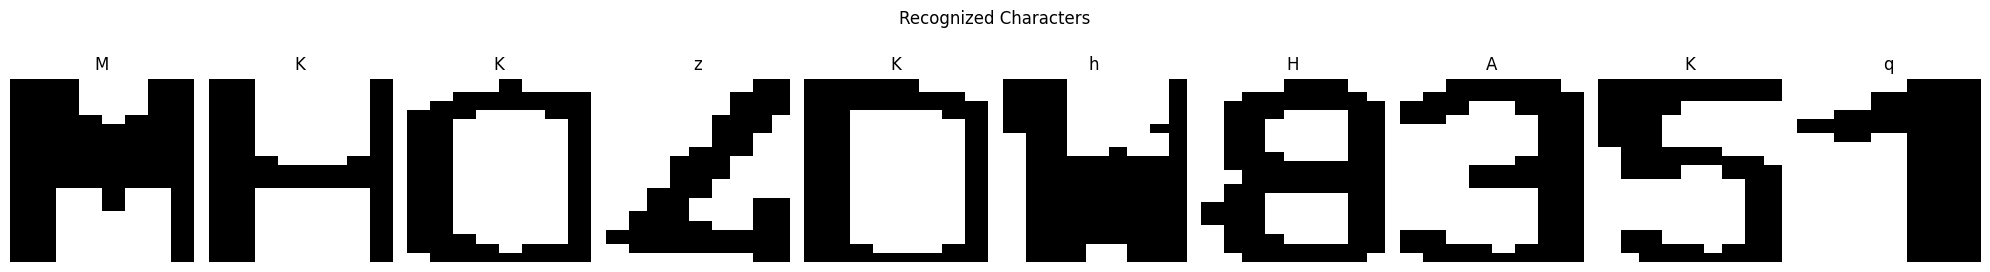

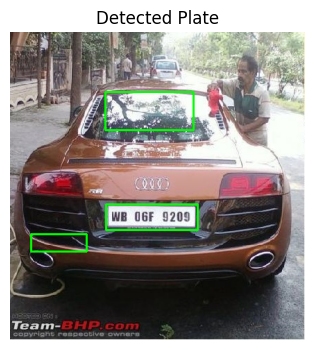

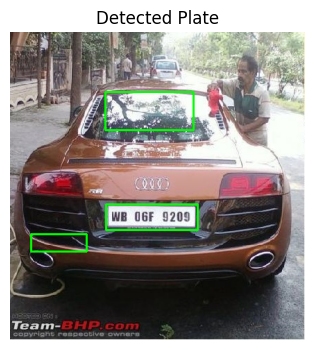

Detected Plate Text: 


In [ ]:
for image_number, image_path in enumerate(image_paths[:5], start=1):


    car_image = cv2.imread(image_path)
    rgb_image = cv2.cvtColor(car_image, cv2.COLOR_BGR2RGB)
    gray_image = convertRGBToGrayscale(rgb_image)

    smooth_image = gaussian(gray_image)
    edge_image = sobel(smooth_image)
    # binary_image = binaryThreshold(edge_image, 100)
    _, binary_image = cv2.threshold(edge_image, 50, 255, cv2.THRESH_BINARY)
    dilated_image = dilationBlack(binary_image)
    cleaned_image = erosionBlack(dilated_image)
    regions = connectedComponents(cleaned_image)
    result, regions = detectPlateRegions(car_image, regions)
    # detected_regions = connectedComponents(cleaned_image)

    # result_image, plate_regions = detectPlateRegions(
    #     rgb_image,
    #     detected_regions
    # )

    plt.figure(figsize=(8,4))
    plt.imshow(result_image)
    plt.title("Detected Plate")
    plt.axis('off')
    plt.show()

    results = extractCharacters(car_image, regions, edge_image)

    for plate_idx, plate_data in enumerate(results):

        recognized_text = recognizePlate(
            plate_data["characters"],
            train_features,
            train_labels
        )

        print("Detected Plate Text:", recognized_text)

        chars = plate_data["characters"]

        if chars:
            n = len(chars)
            fig, axes = plt.subplots(1, n, figsize=(n * 2, 3))

            if n == 1:
                axes = [axes]

            for idx, ch in enumerate(chars):
                axes[idx].imshow(ch["image"], cmap='gray')
                axes[idx].set_title(recognized_text[idx] if idx < len(recognized_text) else "?")
                axes[idx].axis('off')

            plt.suptitle("Recognized Characters")
            plt.tight_layout()
            plt.show()

In [ ]:
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split

# Shuffle dataset first
train_features, train_labels = shuffle(
    train_features,
    train_labels,
    random_state=42
)

# Reduce size AFTER shuffling
train_features = train_features[:3000]
train_labels = train_labels[:3000]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    train_features,
    train_labels,
    test_size=0.2,
    random_state=42
)

correct = 0
total = 0

for i in range(len(X_test)):

    prediction = knnPredict(
        X_test[i],
        X_train,
        y_train,
        k=3
    )

    if prediction == y_test[i]:
        correct += 1

    total += 1

accuracy = correct / total * 100

print("Test Accuracy:", accuracy)

Test Accuracy: 68.83333333333333


### OCR Pipeline

========== IMAGE 1 ==========


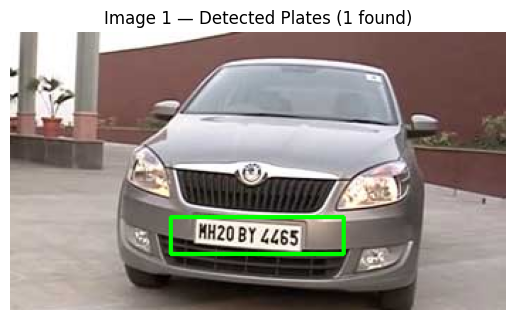

  Plate 1: 10 character(s) found


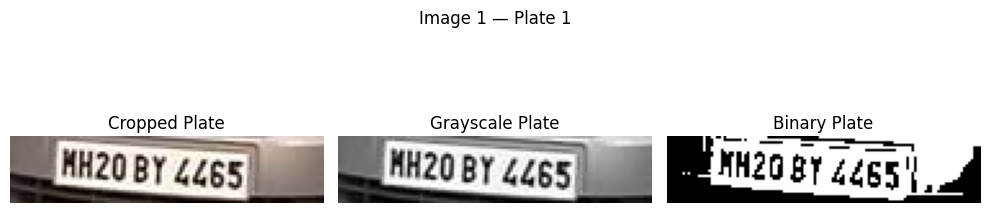

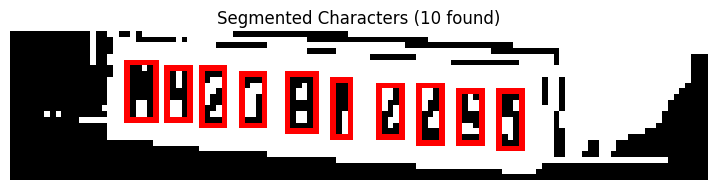

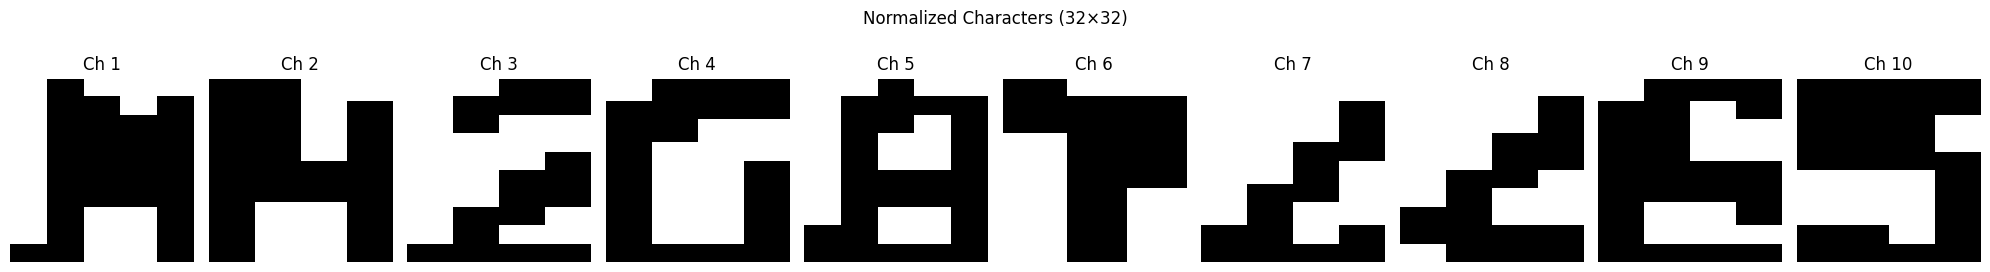

EasyOCR Result:
MHZO BY LL6S
========== IMAGE 2 ==========


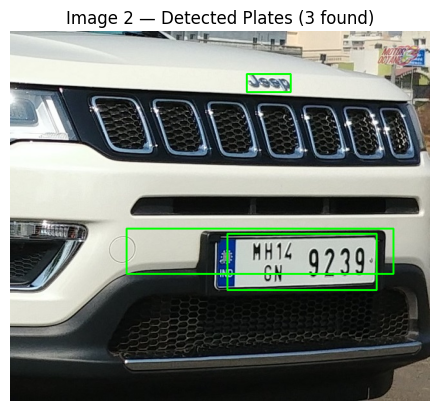

  Plate 1: 8 character(s) found


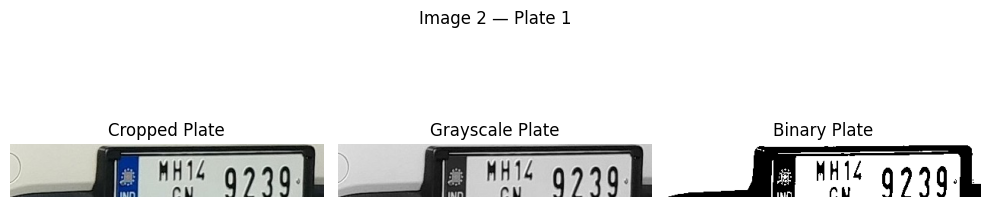

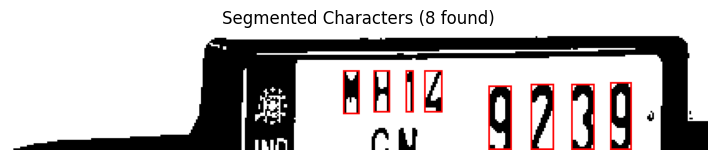

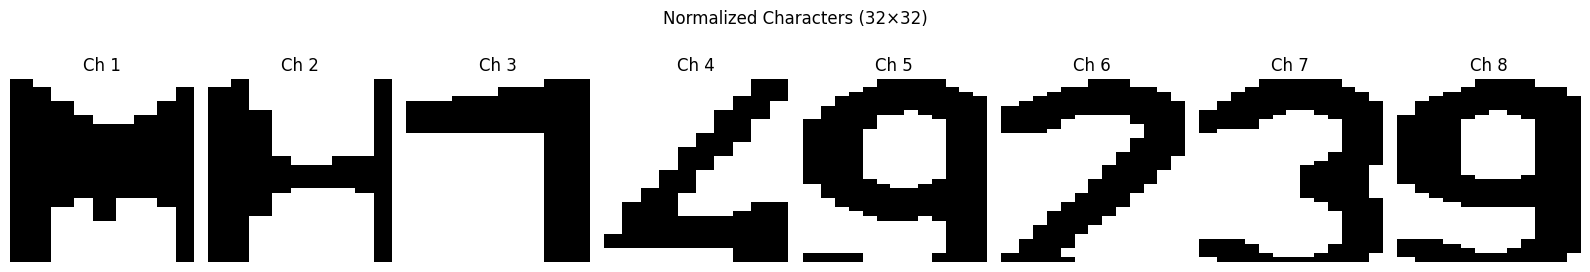

EasyOCR Result:
MhIL 9239_
========== IMAGE 3 ==========


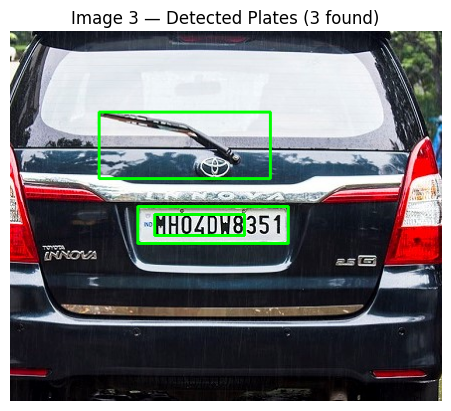

  Plate 1: 0 character(s) found


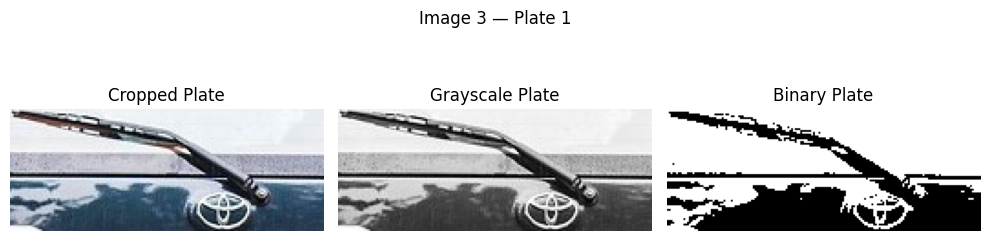

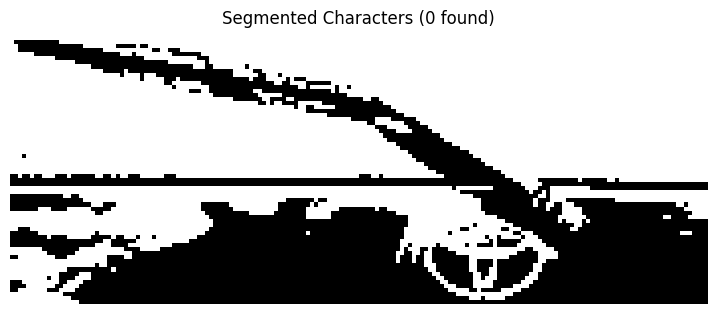

EasyOCR Result:
========== IMAGE 4 ==========


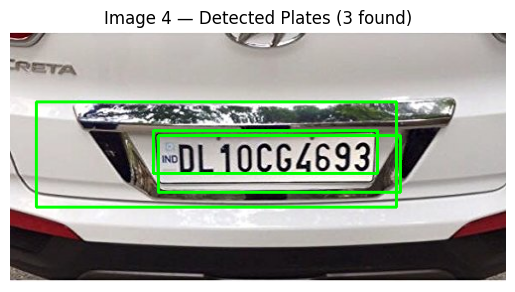

  Plate 1: 10 character(s) found


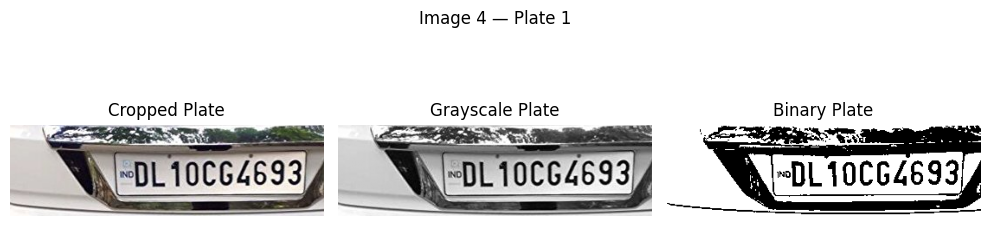

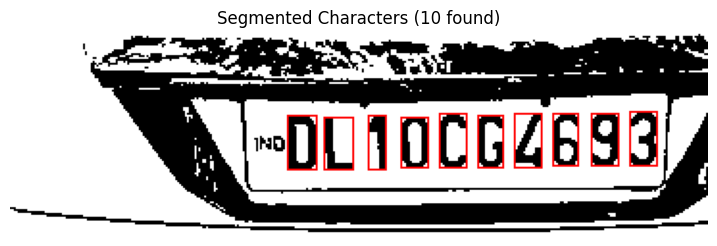

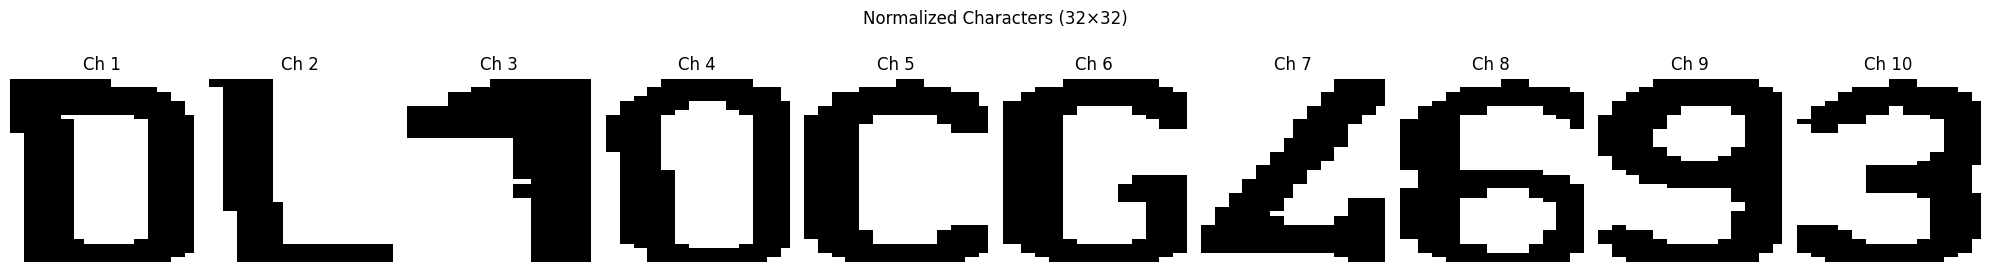

EasyOCR Result:
~DL10CG4693
========== IMAGE 5 ==========


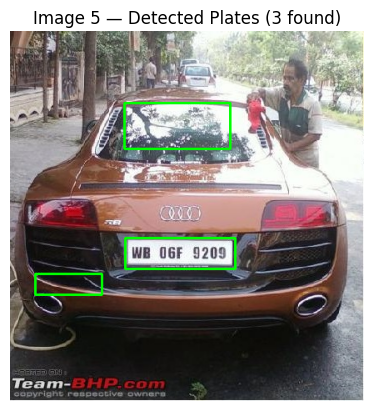

  Plate 1: 9 character(s) found


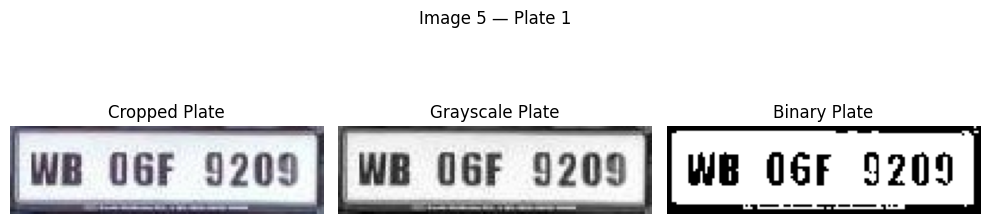

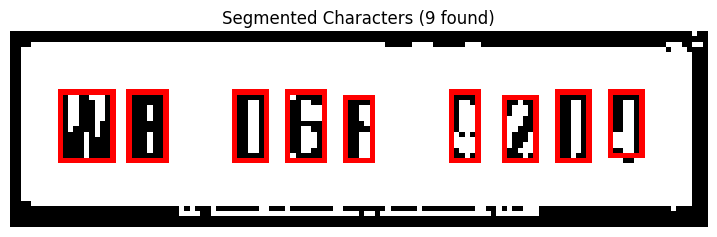

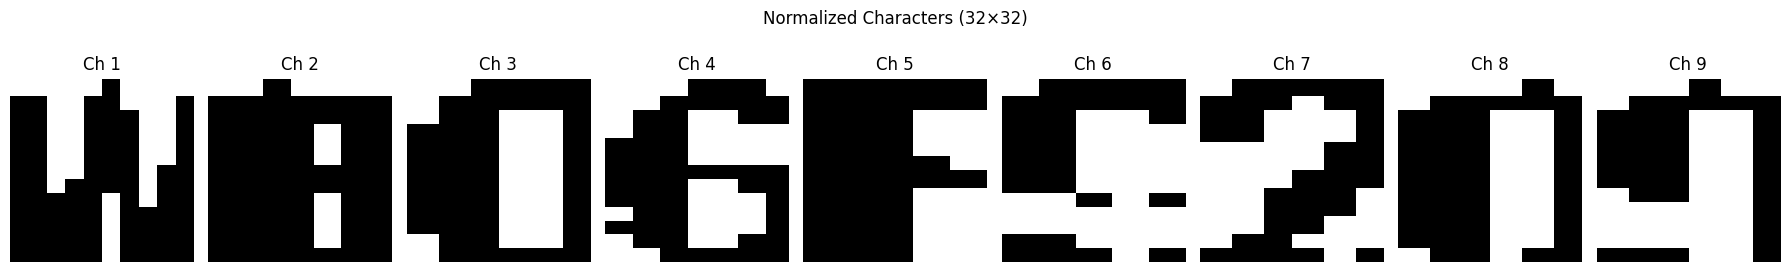

EasyOCR Result:
WB  Q6F   9209


In [ ]:
!pip install easyocr
import easyocr
all_detected_results = []

reader = easyocr.Reader(['en'])

for image_number, image_path in enumerate(image_paths[:5], start=1):

    print(f"========== IMAGE {image_number} ==========")

    car_image = cv2.imread(image_path)
    rgb_image = cv2.cvtColor(car_image, cv2.COLOR_BGR2RGB)

    # Step 1: Convert to grayscale
    gray_image = convertRGBToGrayscale(rgb_image)

    # Step 2: Remove noise
    smooth_image = gaussian(gray_image)

    # Step 3: Detect edges
    edge_image = sobel(smooth_image)

    # Step 4: Convert to binary image
    binary_image = binaryThreshold(edge_image, 100)

    # Step 5: Morphological operations
    dilated_image = dilationBlack(binary_image)
    cleaned_image = erosionBlack(dilated_image)

    # Step 6: Connected components
    detected_regions = connectedComponents(cleaned_image)

    # Step 7: Detect possible plates
    result_image, plate_regions = detectPlateRegions(rgb_image, detected_regions)

    plt.imshow(result_image)
    plt.title(f"Image {image_number} — Detected Plates ({len(plate_regions)} found)")
    plt.axis('off')
    plt.show()

    results = extractCharacters(rgb_image, plate_regions, edge_image)

    for plate_idx, plate_data in enumerate(results):
        chars = plate_data["characters"]
        print(f"  Plate {plate_idx + 1}: {len(chars)} character(s) found")

        # Row 1: plate crop → gray → binary
        fig, axes = plt.subplots(1, 3, figsize=(10, 3))
        axes[0].imshow(plate_data["plate_crop"])
        axes[0].set_title("Cropped Plate")
        axes[0].axis("off")

        axes[1].imshow(plate_data["gray_plate"], cmap="gray")
        axes[1].set_title("Grayscale Plate")
        axes[1].axis("off")

        axes[2].imshow(plate_data["binary_plate"], cmap="gray")
        axes[2].set_title("Binary Plate")
        axes[2].axis("off")

        plt.suptitle(f"Image {image_number} — Plate {plate_idx + 1}")
        plt.tight_layout()
        plt.show()

        # Row 2: annotated binary plate showing bounding boxes
        annotated = cv2.cvtColor(
            plate_data["binary_plate"].astype(np.uint8),
            cv2.COLOR_GRAY2RGB
        )

        for ch in chars:
            r1, r2, c1, c2 = ch["bbox"]
            cv2.rectangle(annotated, (c1, r1), (c2, r2), (255, 0, 0), 1)

        plt.figure(figsize=(9, 5))
        plt.imshow(annotated)
        plt.title(f"Segmented Characters ({len(chars)} found)")
        plt.axis("off")
        plt.show()

        # Row 3: normalized characters
        if chars:
            n = len(chars)
            fig, axes = plt.subplots(1, n, figsize=(n * 2, 3))
            if n == 1:
                axes = [axes]
            for idx, ch in enumerate(chars):
                axes[idx].imshow(ch["image"], cmap="gray")
                axes[idx].set_title(f"Ch {idx + 1}")
                axes[idx].axis("off")
            plt.suptitle("Normalized Characters (32×32)")
            plt.tight_layout()
            plt.show()

        # =========================
        # EasyOCR
        # =========================

        plate_crop = plate_data["plate_crop"]

        if len(plate_crop.shape) == 2:
            plate_crop_rgb = cv2.cvtColor(plate_crop, cv2.COLOR_GRAY2RGB)
        else:
            plate_crop_rgb = plate_crop

        result = reader.readtext(plate_crop_rgb)

        print("EasyOCR Result:")
        for detection in result:
            print(detection[1])

        all_detected_results.append({
            "image_number": image_number,
            "plate_index": plate_idx,
            "text": [detection[1] for detection in result]
        })

In [ ]:
print("\n========== ALL DETECTED RESULTS ==========\n")

for item in all_detected_results:
    print(f"Image {item['image_number']} | Plate {item['plate_index']} | Text: {item['text']}")


========== ALL DETECTED RESULTS ==========

Image 1 | Plate 0 | Text: ['MHZO BY LL6S']
Image 2 | Plate 0 | Text: ['MhIL 9239_']
Image 3 | Plate 0 | Text: []
Image 4 | Plate 0 | Text: ['~DL10CG4693']
Image 5 | Plate 0 | Text: ['WB  Q6F   9209']
